# 模型解释性与效果评估

## 目标
深入理解 GNN 模型的预测行为，包括：
1. 模型效果全面评估（ROC-AUC, PR-AUC, Precision/Recall@K）
2. 不同阈值下的业务影响分析
3. 节点嵌入可视化（UMAP）
4. 特征重要性分析
5. 模型错误分析

In [4]:
import sys
sys.path.append('..')

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from src.data.generate_fraud_data import generate_fraud_dataset
from src.data.graph_builder import build_heterogeneous_graph, train_val_test_split_by_nodes
from src.models.hetero_gnn import HeteroGNN
from src.train import train_model
from src.evaluate import (
    compute_metrics, evaluate_gang_detection, precision_at_k,
    evaluate_on_thresholds, find_optimal_threshold,
    visualize_embeddings,
)
from src.utils import set_seed

# 修复 matplotlib 中文显示问题
plt.rcParams['font.sans-serif'] = ['Heiti TC', 'PingFang HK', 'Kaiti SC']
plt.rcParams['axes.unicode_minus'] = False

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")

使用设备: cpu


## 1. 加载数据和已训练模型

（为节省时间，使用较少 epochs 快速训练）

In [5]:
# 数据准备
dataset = generate_fraud_dataset(
    n_users=5000, n_devices=3000, n_ips=2000, n_phones=4000,
    fraud_ratio=0.05, n_gangs=8, seed=42,
)
n_users = dataset['user_features'].shape[0]
train_mask, val_mask, test_mask = train_val_test_split_by_nodes(
    n_users, train_ratio=0.6, val_ratio=0.2, seed=42
)
data = build_heterogeneous_graph(
    node_features_dict={
        'user': dataset['user_features'], 'device': dataset['device_features'],
        'ip': dataset['ip_features'], 'phone': dataset['phone_features'],
    },
    edge_dict={
        ('user', 'uses', 'device'): dataset['user_device_edges'],
        ('user', 'from', 'ip'): dataset['user_ip_edges'],
        ('user', 'has', 'phone'): dataset['user_phone_edges'],
    },
    labels_dict={'user': dataset['labels']},
    train_mask_dict={'user': train_mask},
    val_mask_dict={'user': val_mask},
    test_mask_dict={'user': test_mask},
)

# 训练模型
node_types = ['user', 'device', 'ip', 'phone']
edge_types = [
    ('user', 'uses', 'device'),
    ('user', 'from', 'ip'),
    ('user', 'has', 'phone'),
]
in_channels_dict = {
    'user': 8, 'device': 6, 'ip': 5, 'phone': 4,
}

model = HeteroGNN(
    node_types=node_types, edge_types=edge_types, target_node_type='user',
    in_channels_dict=in_channels_dict,
    hidden_channels=64, out_channels=2, num_layers=2, dropout=0.3,
)

result = train_model(
    model, data, device,
    epochs=150, lr=0.01, weight_decay=5e-4,
    patience=30, use_focal_loss=True, focal_gamma=2.0,
    is_hetero=True, verbose=False,
)

# 获取预测结果
model.eval()
with torch.no_grad():
    out = model(data.x_dict, data.edge_index_dict)
    probs = F.softmax(out, dim=1)
    fraud_scores = probs[:, 1].cpu().numpy()

y_true = dataset['labels'][test_mask]
y_score = fraud_scores[test_mask]

# 找最优阈值
best_threshold, best_f1 = find_optimal_threshold(y_true, y_score, metric='f1')
y_pred_best = (y_score >= best_threshold).astype(int)
print(f"最优阈值: {best_threshold:.3f}, 最优 F1: {best_f1:.4f}")

最优阈值: 0.902, 最优 F1: 1.0000


## 2. 不同阈值下的业务影响分析

在风控中，阈值的选择直接影响**拦截率**和**误拦率**之间的平衡。

不同阈值下的模型表现:
阈值       准确率        精确率        召回率        F1         FPR        FNR       
--------------------------------------------------------------------------------
0.3      0.9670     0.6207     1.0000     0.7660     0.0349     0.0000    
0.4      0.9910     0.8571     1.0000     0.9231     0.0095     0.0000    
0.5      0.9970     0.9474     1.0000     0.9730     0.0032     0.0000    
0.6      0.9980     0.9643     1.0000     0.9818     0.0021     0.0000    
0.7      1.0000     1.0000     1.0000     1.0000     0.0000     0.0000    
0.8      1.0000     1.0000     1.0000     1.0000     0.0000     0.0000    
0.9      1.0000     1.0000     1.0000     1.0000     0.0000     0.0000    

💡 阈值选择策略:
  低阈值 (0.3-0.4): 高召回，适合"宁可错杀不可放过"的场景（如支付欺诈）
  高阈值 (0.7-0.8): 高精确，适合"精准拦截"的场景（如营销活动反作弊）
  中阈值 (0.5-0.6): 平衡，适合大多数场景


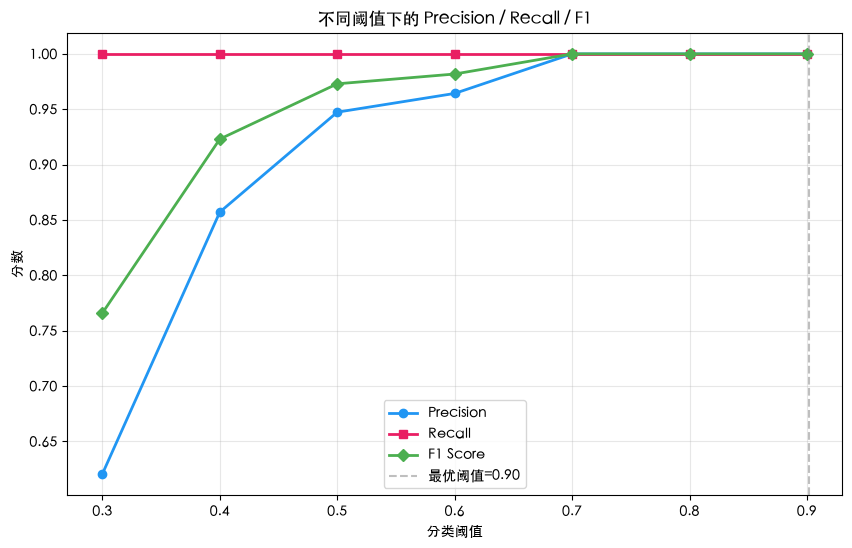

In [6]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
df_thresholds = evaluate_on_thresholds(y_true, y_score, thresholds)

# 打印对比表
print("不同阈值下的模型表现:")
print("=" * 80)
print(f"{'阈值':<8} {'准确率':<10} {'精确率':<10} {'召回率':<10} {'F1':<10} {'FPR':<10} {'FNR':<10}")
print("-" * 80)
for _, row in df_thresholds.iterrows():
    print(f"{row['threshold']:<8.1f} {row['accuracy']:<10.4f} {row['precision']:<10.4f} "
          f"{row['recall']:<10.4f} {row['f1']:<10.4f} "
          f"{row['false_positive_rate']:<10.4f} {row['false_negative_rate']:<10.4f}")

print("\n💡 阈值选择策略:")
print("  低阈值 (0.3-0.4): 高召回，适合\"宁可错杀不可放过\"的场景（如支付欺诈）")
print("  高阈值 (0.7-0.8): 高精确，适合\"精准拦截\"的场景（如营销活动反作弊）")
print("  中阈值 (0.5-0.6): 平衡，适合大多数场景")

# 可视化
fig, ax = plt.subplots(figsize=(10, 6))
x = thresholds
ax.plot(x, df_thresholds['precision'], 'o-', label='Precision', color='#2196F3', linewidth=2)
ax.plot(x, df_thresholds['recall'], 's-', label='Recall', color='#E91E63', linewidth=2)
ax.plot(x, df_thresholds['f1'], 'D-', label='F1 Score', color='#4CAF50', linewidth=2)
ax.axvline(x=best_threshold, color='gray', linestyle='--', alpha=0.5, label=f'最优阈值={best_threshold:.2f}')
ax.set_xlabel('分类阈值')
ax.set_ylabel('分数')
ax.set_title('不同阈值下的 Precision / Recall / F1')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 3. PR 曲线与 ROC 曲线

在类别极不平衡的风控场景中，PR 曲线比 ROC 曲线更能反映模型真实效果。

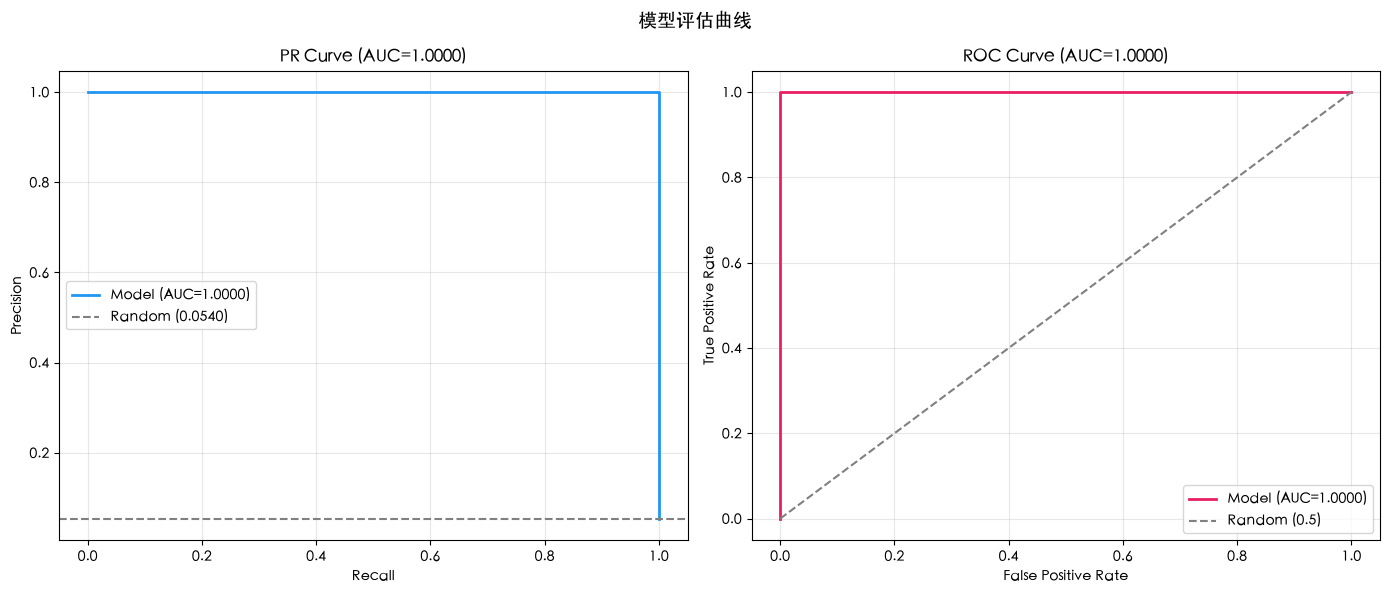

PR-AUC: 1.0000
ROC-AUC: 1.0000

💡 风控场景中，PR-AUC 比 ROC-AUC 更重要：
   在正负比 1:17 的情况下，
   ROC-AUC 可能会乐观估计模型效果，PR-AUC 更能反映真实性能。


In [7]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc

# PR Curve
precision, recall, pr_thresholds = precision_recall_curve(y_true, y_score)
pr_auc = auc(recall, precision)

# ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# 计算随机分类器的基线
random_baseline = y_true.sum() / len(y_true)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PR Curve
axes[0].plot(recall, precision, color='#2196F3', linewidth=2, label=f'Model (AUC={pr_auc:.4f})')
axes[0].axhline(y=random_baseline, color='gray', linestyle='--', label=f'Random ({random_baseline:.4f})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title(f'PR Curve (AUC={pr_auc:.4f})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ROC Curve
axes[1].plot(fpr, tpr, color='#E91E63', linewidth=2, label=f'Model (AUC={roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Random (0.5)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title(f'ROC Curve (AUC={roc_auc:.4f})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('模型评估曲线', fontsize=14)
plt.tight_layout()
plt.show()

print(f"PR-AUC: {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"\n💡 风控场景中，PR-AUC 比 ROC-AUC 更重要：")
print(f"   在正负比 1:{int((len(y_true)-y_true.sum())/max(y_true.sum(), 1))} 的情况下，")
print(f"   ROC-AUC 可能会乐观估计模型效果，PR-AUC 更能反映真实性能。")

## 4. 节点嵌入可视化 (UMAP)

查看 GNN 学到的用户节点嵌入，观察正常用户和欺诈用户是否在嵌入空间中分开。

/Users/ziyi/Demo/1-AI/GCN-Fraud-Detection/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


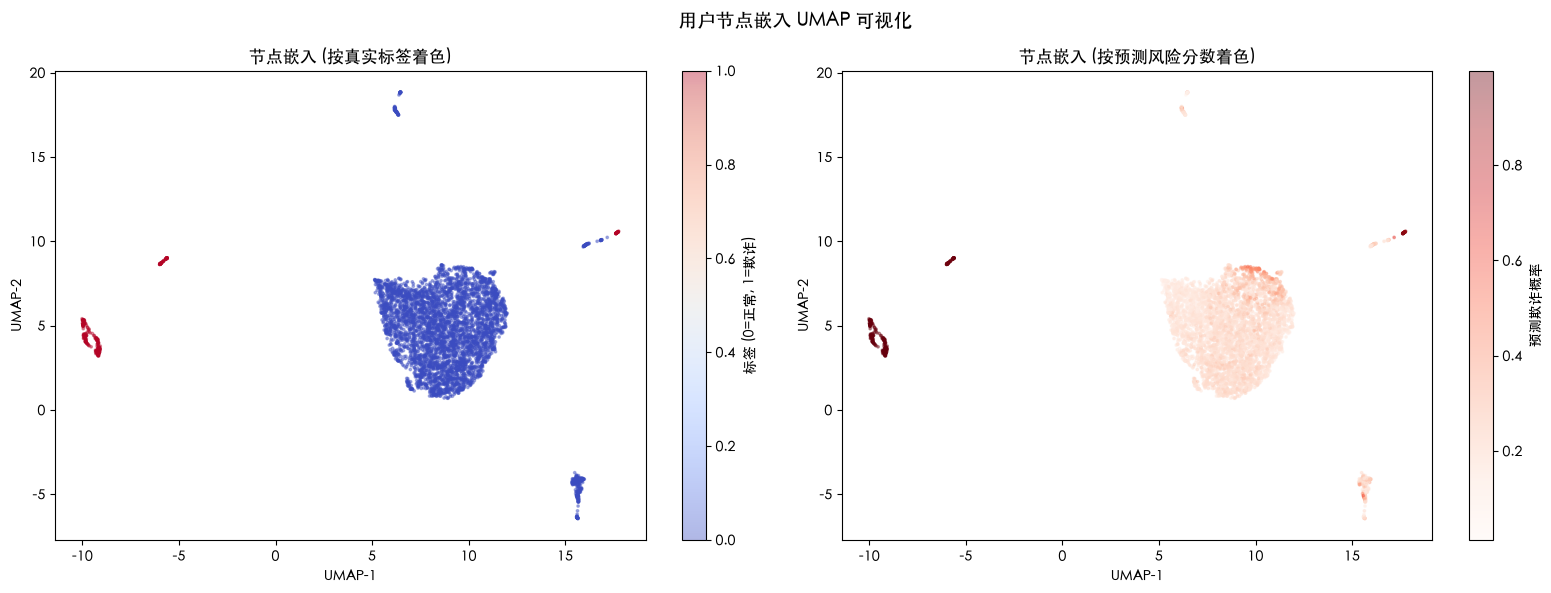

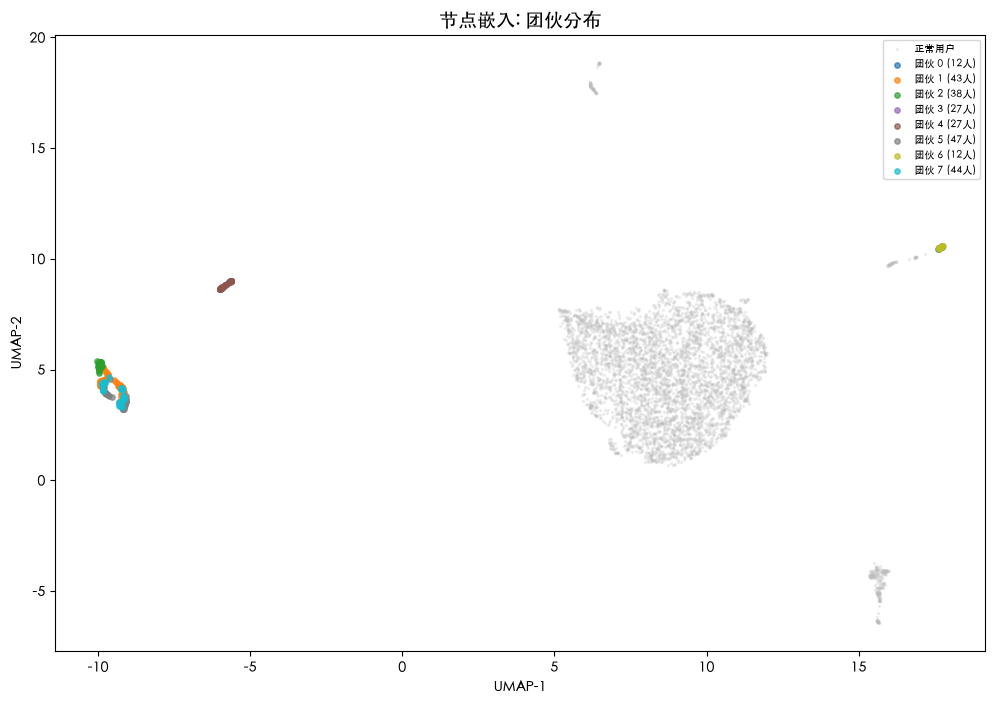

💡 观察要点:
  1. 欺诈用户通常聚集在一起（团伙特征明显）
  2. 有些欺诈用户分散在正常用户中（个体欺诈，更难发现）
  3. 同一团伙的成员通常在嵌入空间中距离较近


In [8]:
# 获取用户节点的嵌入
model.eval()
with torch.no_grad():
    embeddings_dict = model.get_embeddings(data.x_dict, data.edge_index_dict)
    user_embeddings = embeddings_dict['user'].cpu().numpy()

# UMAP 降维
import umap
reducer = umap.UMAP(random_state=42)
coords = reducer.fit_transform(user_embeddings)

# 可视化
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 按真实标签着色
sc1 = axes[0].scatter(coords[:, 0], coords[:, 1],
                      c=dataset['labels'], cmap='coolwarm',
                      alpha=0.4, s=3)
axes[0].set_title('节点嵌入 (按真实标签着色)', fontsize=12)
axes[0].set_xlabel('UMAP-1')
axes[0].set_ylabel('UMAP-2')
plt.colorbar(sc1, ax=axes[0], label='标签 (0=正常, 1=欺诈)')

# 按预测分数着色
sc2 = axes[1].scatter(coords[:, 0], coords[:, 1],
                      c=fraud_scores, cmap='Reds',
                      alpha=0.4, s=3)
axes[1].set_title('节点嵌入 (按预测风险分数着色)', fontsize=12)
axes[1].set_xlabel('UMAP-1')
axes[1].set_ylabel('UMAP-2')
plt.colorbar(sc2, ax=axes[1], label='预测欺诈概率')

plt.suptitle('用户节点嵌入 UMAP 可视化', fontsize=14)
plt.tight_layout()
plt.show()

# 标注团伙
gang_ids = dataset['gang_ids']
fig, ax = plt.subplots(figsize=(12, 8))
# 正常用户
normal_mask = (gang_ids == -1) & (dataset['labels'] == 0)
ax.scatter(coords[normal_mask, 0], coords[normal_mask, 1],
           c='#BDBDBD', alpha=0.2, s=2, label='正常用户')

# 各团伙用不同颜色
gang_colors = plt.cm.tab10(np.linspace(0, 1, 8))
for gid in range(8):
    gang_mask = gang_ids == gid
    ax.scatter(coords[gang_mask, 0], coords[gang_mask, 1],
               c=[gang_colors[gid]], alpha=0.7, s=15,
               label=f'团伙 {gid} ({gang_mask.sum()}人)')

ax.set_title('节点嵌入: 团伙分布', fontsize=14)
ax.set_xlabel('UMAP-1')
ax.set_ylabel('UMAP-2')
ax.legend(fontsize=7, loc='upper right')
plt.show()

print("💡 观察要点:")
print("  1. 欺诈用户通常聚集在一起（团伙特征明显）")
print("  2. 有些欺诈用户分散在正常用户中（个体欺诈，更难发现）")
print("  3. 同一团伙的成员通常在嵌入空间中距离较近")

## 5. 模型错误分析

了解模型在哪些样本上犯错，可以帮助我们改进模型和策略。

In [9]:
# 分析各类错误的特征
y_pred_all = (fraud_scores >= best_threshold).astype(int)
y_true_all = dataset['labels']

# 分类：TP, FP, FN, TN
tp_mask = (y_true_all == 1) & (y_pred_all == 1)
fp_mask = (y_true_all == 0) & (y_pred_all == 1)
fn_mask = (y_true_all == 1) & (y_pred_all == 0)
tn_mask = (y_true_all == 0) & (y_pred_all == 0)

print("错误分析:")
print(f"  真阳性 (TP - 正确拦截): {tp_mask.sum()} 个")
print(f"  假阳性 (FP - 误拦):      {fp_mask.sum()} 个")
print(f"  假阴性 (FN - 漏网):      {fn_mask.sum()} 个")
print(f"  真阴性 (TN - 正确放行):  {tn_mask.sum()} 个")

# 对比 FN（漏网）和 TP（正确拦截）的用户特征
user_feat = dataset['user_features']
feature_names = dataset['feature_names']['user']

print(f"\n漏网用户 (FN) vs 正确拦截用户 (TP) 的特征对比:")
print(f"{'特征名':<15s} {'TP均值':>10s} {'FN均值':>10s} {'差异':>10s}")
print(f"{'-'*47}")

for i, name in enumerate(feature_names):
    tp_mean = user_feat[tp_mask, i].mean() if tp_mask.sum() > 0 else 0
    fn_mean = user_feat[fn_mask, i].mean() if fn_mask.sum() > 0 else 0
    diff = tp_mean - fn_mean
    print(f"{name:<15s} {tp_mean:10.3f} {fn_mean:10.3f} {diff:+10.3f}")

print(f"\n💡 漏网用户的特征更接近正常用户——这正是 GNN 能够发挥作用的地方：")
print(f"   虽然单点特征不明显，但他们的图结构连接模式会暴露他们。")

错误分析:
  真阳性 (TP - 正确拦截): 247 个
  假阳性 (FP - 误拦):      0 个
  假阴性 (FN - 漏网):      3 个
  真阴性 (TN - 正确放行):  4750 个

漏网用户 (FN) vs 正确拦截用户 (TP) 的特征对比:
特征名                   TP均值       FN均值         差异
-----------------------------------------------
注册天数                10.215      8.247     +1.969
活跃度评分                0.787      0.705     +0.082
设备更换次数               5.227      4.691     +0.535
平均交易金额              22.683     16.823     +5.859
7天登录次数              14.981     11.939     +3.042
账号等级                 0.478      0.358     +0.120
是否实名                 0.159      0.052     +0.107
好友关注数                2.103      2.402     -0.299

💡 漏网用户的特征更接近正常用户——这正是 GNN 能够发挥作用的地方：
   虽然单点特征不明显，但他们的图结构连接模式会暴露他们。


## 关键要点总结

1. **PR-AUC** 是风控场景下最重要的评估指标（类别极不平衡时 ROC-AUC 可能过于乐观）
2. **阈值选择**需要在精确率和召回率之间权衡，取决于具体业务场景
3. **节点嵌入**可视化可以直观展示模型学到的表示质量
4. **错误分析**（尤其是假阴性分析）是模型迭代优化的关键输入
5. GNN 能发现「单看正常、关联异常」的隐蔽欺诈 —— 这是其核心价值

> **下一步**：了解如何将模型部署到生产环境，请参考 `docs/05-模型部署与上线指南.md`